# 왜 *지배구조(G)* 만 살아남았는가? — 4가지 가설 검증

> **배경**: 3트랙 종합(`종합_기록.md`)에서 길이·규모·업종·연도를 **완전통제**하면 텍스트–등급
> 연관은 대부분 사라지는데, **seed TF‑IDF 트랙에서만 *지배구조(G)* 가 강건하게 생존**한다
> (매칭 회귀 **0.38\*\***, 부분 Spearman 대각 **0.17**, 기업 부트 CI 0 제외). E는 경계, S는 null.
> 이 노트북은 *"왜 하필 G인가?"* 를 **4개 경쟁가설**로 분해해 답한다.
>
> | 가설 | 주장 | 한 줄 |
> |---|---|---|
> | **H1** KCGS 평가구조 | 통합등급이 구조적으로 G에 유리 | E:S:G 가중이 G에 쏠려 있으면 통합등급≈G |
> | **H2** G 측정가능성 | G는 텍스트로 재기 쉬운 차원 | 거버넌스 용어가 구체적이라 변별됨 |
> | **H3** 사전 품질 | E/S 사전이 부실해서 G만 | E=산업일반어, S=광의어, G=구체어 |
> | **H4** Dense 실패 | 임베딩이 왜 TF‑IDF만 못한가 | 차원분리·문장누수·길이 |
>
> **방법 규약(3트랙 통일안 재사용 — `synth_lib.py`)**: 순서형 `OrderedModel(logit)` + 기업 cluster SE,
> z‑score(ddof=0), 부분 Spearman=순위 잔차화, 완전통제 = {길이=log(II+IV+VI 문자수), 규모=log 자산,
> 업종 8더미, 연도}. **인과 아님(연관·예측)**. p값과 효과크기(계수·ρ·CI) 병기. 결론 뒤집기용 스펙서치 금지.
> 분석 엔진은 `analysis/08_why_g.py`(표 `data/processed/08_*.csv`), TF‑IDF 재구성은 committed 값과 1e‑16 일치.

In [1]:
import sys; from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams
ROOT = Path('/Users/home1/esg-dart-project'); DP = ROOT/'data/processed'; FIG = ROOT/'reports/figures'
sys.path.insert(0, str(ROOT/'analysis'))
import importlib, synth_lib as S; importlib.reload(S)
import importlib.util
for fn in ['AppleGothic','NanumGothic','Malgun Gothic']:
    if fn in {f.name for f in font_manager.fontManager.ttflist}:
        rcParams['font.family']=fn; break
rcParams['axes.unicode_minus']=False; rcParams['figure.dpi']=110
pd.set_option('display.width',200); pd.set_option('display.max_columns',30); pd.set_option('display.max_colwidth',70)
L = lambda n: pd.read_csv(DP/f'08_{n}.csv')
df = pd.read_csv(S.SYNTH_TBL, dtype={'stock_code_str':str})
print('종합 테이블', df.shape, '| 08_* 표', len(list(DP.glob('08_*.csv'))),'개 로드 준비 완료')

종합 테이블 (381, 50) | 08_* 표 16 개 로드 준비 완료


## H1 — KCGS 평가구조 가설
**검정**: 통합 ESG 등급 대신 **분리된 E/S/G 등급**을 종속변수로 써서 `tfidf_{E,S,G}` × `{e,s,g,ESG}` 의
**3×4 교차회귀**(완전통제 순서형) + 부분 Spearman 을 본다. 그리고 *통합등급 자체가* 어느 하위등급에 실리는지
(`esg_grade_num ~ e+s+g`)를 직접 분해한다. **핵심 질문**: ① 대각(자기차원)이 지배하나? ② `tfidf_G→G` 가
`tfidf_G→ESG_total` 보다 강한가(약하면 통합구조 덕)?

▶ 부분 Spearman 3×4 (길이+규모 통제) — 행=tfidf, 열=등급


,E,S,G,ESG
tfidf,,,,
E,0.198,0.129,-0.013,0.098
S,0.023,0.095,0.056,0.080
G,-0.049,0.082,0.173,0.145


▶ 완전통제 순서형 계수 (별=유의)


,E,S,G,ESG
tfidf,,,,
E,0.298,0.337*,0.409*,0.437*
S,-0.25,0.004,0.123,0.072
G,0.199,0.378*,0.378**,0.495***


▶ 통합 ESG 등급 = 어느 하위등급으로 구성되나 (표준화 OLS, R²=0.965)


,sub_grade,corr_with_ESG,ols_beta_std,ols_p
0,E,0.832,0.375,0.0
1,S,0.822,0.438,0.0
2,G,0.927,0.921,0.0


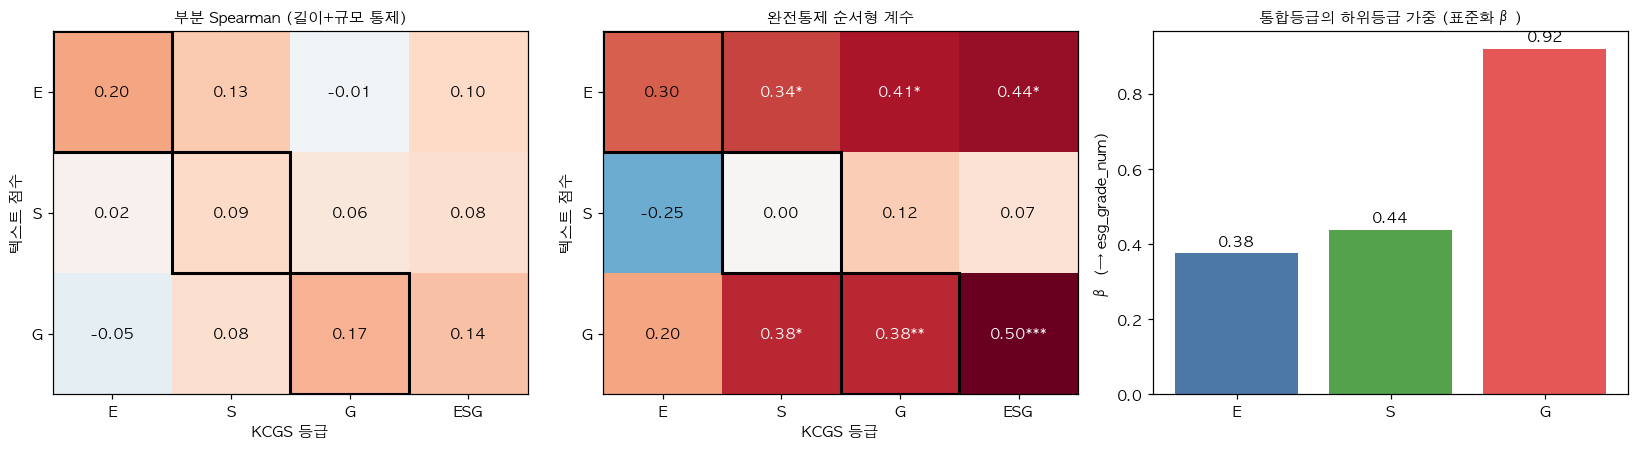

In [2]:
raw=L('h1_raw_spearman_3x4').set_index('Unnamed: 0'); raw.index.name='tfidf'
part=L('h1_partial_spearman_3x4').set_index('Unnamed: 0'); part.index.name='tfidf'
coef=L('h1_fullcontrol_coef_3x4').set_index('Unnamed: 0'); coef.index.name='tfidf'
pval=L('h1_fullcontrol_pval_3x4').set_index('Unnamed: 0'); pval.index.name='tfidf'
dec=L('h1_esg_decomposition')
print('▶ 부분 Spearman 3×4 (길이+규모 통제) — 행=tfidf, 열=등급'); display(part.round(3))
print('▶ 완전통제 순서형 계수 (별=유의)')
star=coef.round(3).astype(str)+pval.map(S.sig_stars)
display(star)
print('▶ 통합 ESG 등급 = 어느 하위등급으로 구성되나 (표준화 OLS, R²=0.965)'); display(dec.round(3))

fig,ax=plt.subplots(1,3,figsize=(15,4.2))
import matplotlib.colors as mcol
for a,(M,t) in zip(ax[:2],[(part,'부분 Spearman (길이+규모 통제)'),(coef,'완전통제 순서형 계수')]):
    im=a.imshow(M.values.astype(float),cmap='RdBu_r',vmin=-0.5,vmax=0.5,aspect='auto')
    a.set_xticks(range(4));a.set_xticklabels(M.columns);a.set_yticks(range(3));a.set_yticklabels(M.index)
    for i in range(3):
        for j in range(4):
            s=S.sig_stars(pval.values[i,j]) if t.startswith('완전') else ''
            a.text(j,i,f'{M.values[i,j]:.2f}{s}',ha='center',va='center',fontsize=10,
                   color='white' if abs(M.values[i,j])>0.3 else 'black')
    a.set_title(t,fontsize=10); a.set_xlabel('KCGS 등급'); a.set_ylabel('텍스트 점수')
    # 대각 강조 (E,S,G 칸)
    for k in range(3): a.add_patch(plt.Rectangle((k-.5,k-.5),1,1,fill=False,ec='k',lw=2))
ax[2].bar(dec['sub_grade'],dec['ols_beta_std'],color=['#4C78A8','#54A24B','#E45756'])
ax[2].set_title('통합등급의 하위등급 가중 (표준화 β)',fontsize=10); ax[2].set_ylabel('β (→ esg_grade_num)')
for i,v in enumerate(dec['ols_beta_std']): ax[2].text(i,v+.02,f'{v:.2f}',ha='center')
plt.tight_layout(); plt.savefig(FIG/'08_h1_kcgs_structure.png',bbox_inches='tight'); plt.show()

**해석 가이드 (H1 = 부분지지·증폭요인)**
- **통합 ESG 등급은 사실상 G 등급이다.** `esg_grade_num`을 분해하면 **G 가중이 β=0.92로 압도**(E 0.38·S 0.44),
  G↔통합 상관 0.93. 즉 *"텍스트가 통합등급을 예측"≈"텍스트가 G를 예측"*. 그래서 완전통제 12칸 중 **`tfidf_G→통합ESG`
  (계수 0.50, p<.001)가 최강**이고, 모든 텍스트가 자기 분리등급보다 통합등급을 더 강하게 예측한다 → **H1 지지 증거**.
- **그러나 통합구조를 걷어내도 G만 산다.** 분리된 *g등급* 만 써도 `tfidf_G→g` 0.38(p.003), 부분상관 대각 **G 0.17이
  행 최댓값**이고 `tfidf_G→g(0.17) > tfidf_G→ESG(0.15)`. 반면 E는 자기 e등급에 비유의(p.12), S는 null(p.98).
  **G는 통합이든 분리든 유일 생존** → 통합구조가 *유일 생존의* 원인은 아니다.
- **결론**: H1은 *"왜 통합분석에서 G가 가장 두드러지나"* 를 설명하는 **실재하는 증폭요인**이지만,
  *"왜 G만 살아남나"* 의 **근본원인은 아니다**(분리등급에서도 G만 생존). → **부분지지**.

## H2 — G 측정가능성 가설
**검정**: `tfidf_G` 상·하위 10기업의 실제 문장과, **무엇이 `tfidf_G`를 끄는가**(per‑term)를 본다.
가설의 키워드(감사위원회·사외이사·의결권 …)를 **선택적 컴플라이언스·윤리 어휘(DRIVER)** vs
**의무 보일러플레이트(이사회·사외이사·감사위원·주주총회, BOILER)** 로 나눠 등급과의 연관을 비교한다.

▶ tfidf_G 를 실제로 끄는 term (per-term, ρ=등급상관, df%=문서출현율)


,vocab_term,doc_freq_pct,mean_tfidf,rho_own_grade
0,플라이,32.0,0.00267,0.433
1,언스,31.0,0.00264,0.429
2,compliance,26.5,0.00397,0.376
3,윤리,54.6,0.00429,0.333
4,방지,79.8,0.01198,0.331
5,부패,19.2,0.00139,0.252
6,rights,2.4,0.00018,0.179
7,의결권,4.7,0.00025,0.164


▶ 거버넌스 키워드 밀도 ↔ tfidf_G·g등급 상관 (선택적 DRIVER vs 보일러플레이트)


,keyword_group,rho_with_tfidf_G,rho_with_g_grade
0,DRIVER(윤리·준법·컴플라이언스·부패방지),0.412,0.285
1,BOILERPLATE(이사회·사외이사·감사위원·주주총회),-0.190,-0.192


▶ 상위10 vs 하위10 tfidf_G 기업


,metric,top10_mean,bot10_mean
0,DRIVER 밀도(/100문장),2.15,0.66
1,BOILER 밀도(/100문장),15.19,22.42
2,g_grade,3.50,1.40
3,문장 수(길이),383.60,198.90


▶ 상위10 tfidf_G 기업 — 대표 컴플라이언스/윤리 문장


,company,tfidf_G,g_grade,driver_density,rep_driver_sentence
0,대한전선,0.2186,3,1.37,준법지원인 등의 주요 활동내역 및 그 처리결과 점검일시 주요 점검내용 점검 및 처리결과 24년 01월 - 협력사 CP ...
1,CJ프레시웨이,0.1409,3,4.15,"컴플라이언스교육 상시 - 교육대상 : 경영리더, 사외이사, 코디네이터, 내부심사원, 실무담당자, 경력/신규 입사자 - ..."
2,CJ제일제당,0.1386,4,0.58,이사회 보고 완료( Compliance 모니터링 및 프로세스 개선 활동 상시 - 공정거래법 관련 부당공동행위 모니터링 ...
3,세아베스틸지주,0.1317,4,1.97,컴플라이언스팀 활동 현황 항목 일시 및 빈도 주요 활동내역 처리 결과 Compliance 체계구축 베스틸지주 산하 준법...
4,CJ제일제당,0.1194,3,0.81,"( 식품 및 바이오 제품의 개발 , 생산 , 유통 , 판매의 전체 V/C) - 인증 항목 : Compliance 경영시..."
5,CJ프레시웨이,0.1181,3,3.77,"컴플라이언스교육 상시 - 신규입사자, 전사, 부문별 담당자, 코디네이터, 협력사 대상 교육진행 (총15회) 기본/공통/..."
6,한진,0.1162,4,1.65,감사위원회 교육실시 현황 교육일자 교육실시주체 참석 감사위원 불참시 사유 주요 교육내용 ACF감사위원회포럼 한종철 이사...
7,CJ대한통운,0.1142,3,2.60,그리고 이해관계자 가치 창출을 위한 윤리경영을 강화하고자 2021년 국내 물류기업 최초로 ISO (컴플라이언스 경영시스...
8,포스코퓨처엠,0.1127,4,2.96,"감사위원회 교육 실시 계획- 관련 규정의 제, 개정 사항 등 년 1회 이상 내, 외부 교육 실시 예정 감사위원회 교육실..."
9,세아베스틸지주,0.1065,4,1.69,준법지원인에 관한 사항 (1) 준법지원인 선임현황 성명 성별 출생년월 직위 상근여부 약력 비 고 오승민 여 이사 상근 ...


▶ 하위10 — 의무 보일러플레이트만


,company,tfidf_G,g_grade,driver_density,rep_driver_sentence
0,제일연마,0.0,2,0.57,감사위원회 교육실시 현황 교육일자 교육실시주체 참석 감사위원 불참시 사유 주요 교육내용 2022년 12월 23일 재무팀...
1,가온전선,0.0,2,1.20,특히 준법경영과 지속가능경영이 중요한 이슈로 부각되는 가운데 감사위원회가견제와 균형의 역할을 다하도록 점검하는 등 회사...
2,BYC,0.0,1,1.23,필요시에는 교육을 실시할 예정입니다 감사위원회 지원조직 현황 부서(팀)명 직원수(명) 직위(근속연수) 주요 활동내역 법...
3,대한전선,0.0,3,0.36,"감사위원회 교육실시 현황 교육일자 교육실시주체 참석 감사위원 불참시 사유 주요 교육내용 외부감사인 박경서, 이병국, 이..."
4,CS홀딩스,0.0,2,0.60,감사위원회 지원조직 현황 부서(팀)명 직원수(명) 직위(근속연수) 주요 활동내역 회계팀 2 - 팀장 1명 (2년)- 책...


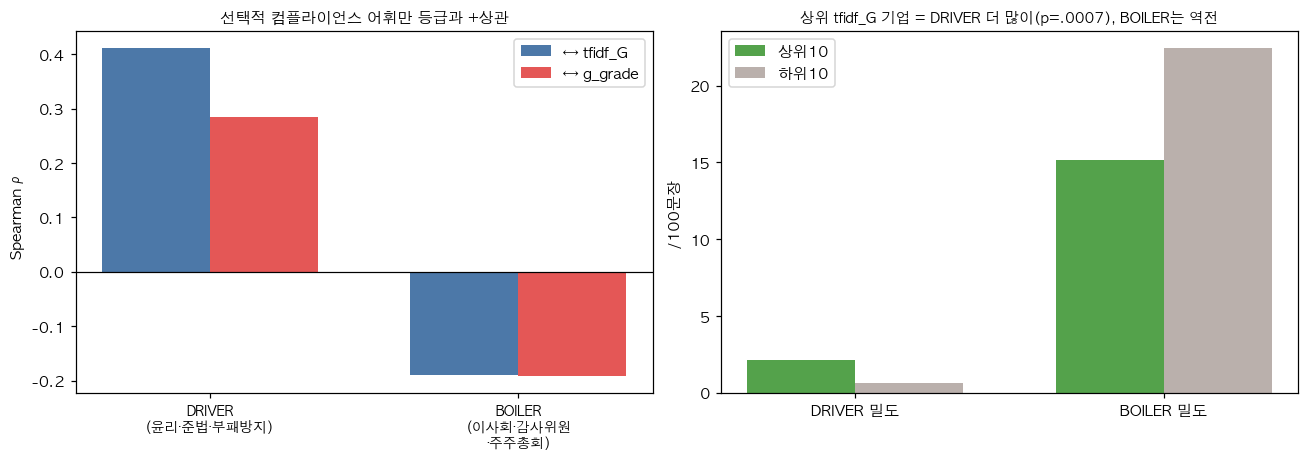

In [3]:
g_terms = L('h3_perterm_quality').query("dimension=='G'").sort_values('rho_own_grade',ascending=False)
corr=L('h2_keyword_density_corr'); cmp=L('h2_top_vs_bottom'); det=L('h2_company_sentences')
print('▶ tfidf_G 를 실제로 끄는 term (per-term, ρ=등급상관, df%=문서출현율)')
display(g_terms[['vocab_term','doc_freq_pct','mean_tfidf','rho_own_grade']].head(8).reset_index(drop=True))
print('▶ 거버넌스 키워드 밀도 ↔ tfidf_G·g등급 상관 (선택적 DRIVER vs 보일러플레이트)'); display(corr)
print('▶ 상위10 vs 하위10 tfidf_G 기업'); display(cmp)
print('▶ 상위10 tfidf_G 기업 — 대표 컴플라이언스/윤리 문장');
display(det[det.grp.str.startswith('상위')][['company','tfidf_G','g_grade','driver_density','rep_driver_sentence']].reset_index(drop=True))
print('▶ 하위10 — 의무 보일러플레이트만');
display(det[det.grp.str.startswith('하위')][['company','tfidf_G','g_grade','driver_density','rep_driver_sentence']].head(5).reset_index(drop=True))

fig,ax=plt.subplots(1,2,figsize=(12,4.3))
x=np.arange(2);w=0.35
ax[0].bar(x-w/2,corr['rho_with_tfidf_G'],w,label='↔ tfidf_G',color='#4C78A8')
ax[0].bar(x+w/2,corr['rho_with_g_grade'],w,label='↔ g_grade',color='#E45756')
ax[0].axhline(0,color='k',lw=.8);ax[0].set_xticks(x)
ax[0].set_xticklabels(['DRIVER\n(윤리·준법·부패방지)','BOILER\n(이사회·감사위원\n·주주총회)'],fontsize=9)
ax[0].set_ylabel('Spearman ρ'); ax[0].set_title('선택적 컴플라이언스 어휘만 등급과 +상관',fontsize=10); ax[0].legend()
gt=cmp.set_index('metric')
ax[1].bar(x-w/2,[gt.loc['DRIVER 밀도(/100문장)','top10_mean'],gt.loc['BOILER 밀도(/100문장)','top10_mean']],w,label='상위10',color='#54A24B')
ax[1].bar(x+w/2,[gt.loc['DRIVER 밀도(/100문장)','bot10_mean'],gt.loc['BOILER 밀도(/100문장)','bot10_mean']],w,label='하위10',color='#BAB0AC')
ax[1].set_xticks(x);ax[1].set_xticklabels(['DRIVER 밀도','BOILER 밀도']);ax[1].set_ylabel('/100문장')
ax[1].set_title('상위 tfidf_G 기업 = DRIVER 더 많이(p=.0007), BOILER는 역전',fontsize=9.5); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG/'08_h2_measurability.png',bbox_inches='tight'); plt.show()

**해석 가이드 (H2 = 강한 지지, 단 통념 보정)**
- **G는 텍스트로 잴 수 있다 — 그러나 "감사위원회·사외이사" 같은 뻔한 용어가 아니다.** `tfidf_G`를 실제로 끄는 건
  **컴플라이언스(ρ.43)·윤리(.33)·부패방지(.33)** 다. 가설이 지목한 **이사회·사외이사·주주는 거의 모든 보고서에 나와
  `max_df=0.95`가 vocab에서 제거**했고, **감사위원회는 vocab에 있으나 df 2.4%·ρ 0.04로 사실상 기여 0**이다.
- **선택적 컴플라이언스 문장 밀도**는 `tfidf_G`와 **+0.41**, `g등급`과 **+0.29**. 반대로 **보일러플레이트 밀도는 −0.19
  (역신호)**. 상위10 기업(대한전선·CJ제일제당·CJ프레시웨이·한진·세아베스틸 …)은 **준법지원인·컴플라이언스 교육·
  청탁금지법·CP등급 A** 를 풍부히 공시하고, 하위10(제일연마·BYC·CS홀딩스 …)은 **주주총회·감사위원회 활동 같은 의무
  보일러플레이트만** 있다(상위>하위 Mann‑Whitney p=0.0007).
- **결론**: **G가 생존한 가장 직접적 이유** = 거버넌스 공시에는 **변별력 있는 선택적 하위어휘(컴플라이언스·윤리)** 가
  존재하고, 더 높은 G 기업이 이를 *선택적으로 더 많이* 쓴다. 단 신호 자체는 약함(회귀 0.38·부분ρ 0.17·CI 넓음)
  → **"유의하나 강하지 않음"**. (밀도는 길이에 교란되니 통제 회귀가 본증거: `종합_기록`·`TF‑IDF_기록 §12`.)

## H3 — Seed Dictionary 품질 가설
**검정**: E/S/G **각 차원의 매칭된 vocab term 전부**(E20·S14·G11)에 대해 문서출현율(df%)·평균 tfidf·자기등급
상관(ρ)을 본다. *"E는 산업일반어, S는 광의어, G는 구체어"* 인지. (per‑term을 **고르지 않고 전부** 기술만 —
outcome 기반 가지치기는 과적합이라 금지: `TF‑IDF_기록 §13`.)

▶ 차원 요약 (term 수·중앙 df%·평균/최대 자기등급 ρ·양상관 비율)


,dimension,n_terms,median_doc_freq_pct,mean_rho_own,max_rho_own,share_rho_pos
0,E,20,38.7,0.25905,0.467,100.0
1,G,11,19.2,0.24400,0.433,100.0
2,S,14,26.9,0.21450,0.404,100.0


▶ S — 보편어로 희석 (안전·지역·임직원 df 76~91%, 노동 ρ≈0)


,vocab_term,doc_freq_pct,rho_own_grade
0,임직원,76.4,0.404
1,협력사,23.9,0.368
2,안전,90.8,0.276
3,chain,19.7,0.267
4,노사,20.2,0.248
5,중대,65.4,0.241
6,supply,13.1,0.216
7,인권,10.5,0.199
8,공급망,40.7,0.188
9,지역,90.0,0.181


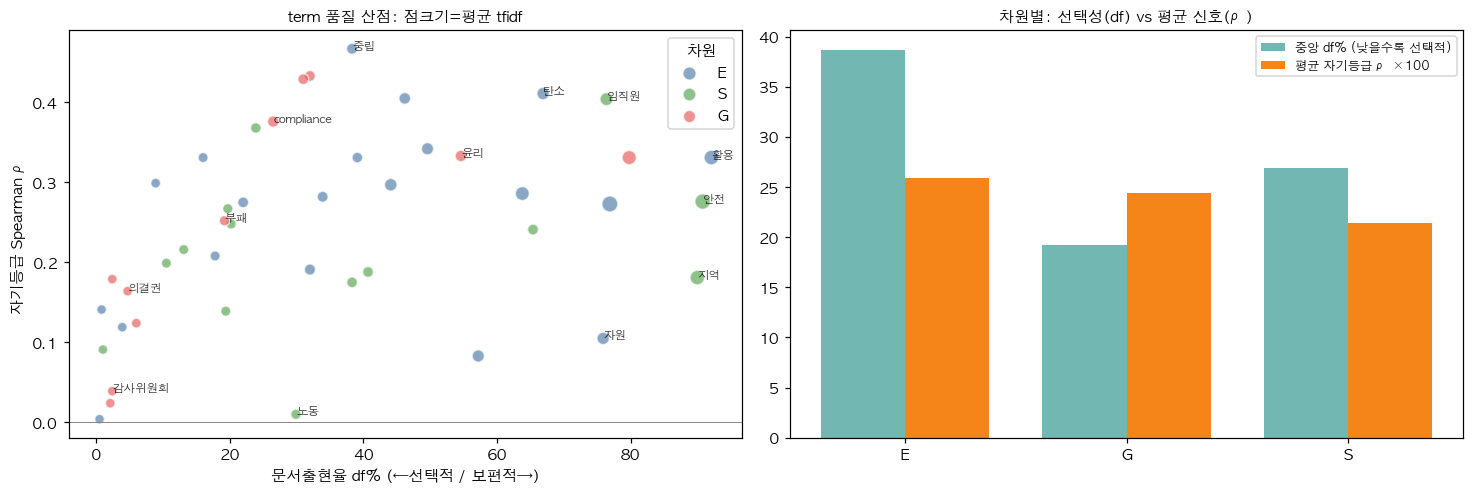

In [4]:
pt=L('h3_perterm_quality'); summ=L('h3_dimension_summary')
print('▶ 차원 요약 (term 수·중앙 df%·평균/최대 자기등급 ρ·양상관 비율)'); display(summ)
print('▶ S — 보편어로 희석 (안전·지역·임직원 df 76~91%, 노동 ρ≈0)')
display(pt.query("dimension=='S'")[['vocab_term','doc_freq_pct','rho_own_grade']].reset_index(drop=True))

col={'E':'#4C78A8','S':'#54A24B','G':'#E45756'}
fig,ax=plt.subplots(1,2,figsize=(13.5,4.6))
for d in ['E','S','G']:
    s=pt[pt.dimension==d]
    ax[0].scatter(s['doc_freq_pct'],s['rho_own_grade'],s=40+s['mean_tfidf']*4000,c=col[d],alpha=.65,label=d,edgecolor='w')
ax[0].axhline(0,color='gray',lw=.6); ax[0].set_xlabel('문서출현율 df% (←선택적 / 보편적→)')
ax[0].set_ylabel('자기등급 Spearman ρ'); ax[0].set_title('term 품질 산점: 점크기=평균 tfidf',fontsize=10); ax[0].legend(title='차원')
for _,r in pt.iterrows():
    if r['vocab_term'] in ['감사위원회','의결권','컴플라이언스','compliance','윤리','부패','탄소','중립','안전','지역','노동','임직원','활용','자원']:
        ax[0].annotate(r['vocab_term'],(r['doc_freq_pct'],r['rho_own_grade']),fontsize=7.5,alpha=.8)
x=np.arange(3); w=0.38
ax[1].bar(x-w/2,summ['median_doc_freq_pct'],w,label='중앙 df% (낮을수록 선택적)',color='#72B7B2')
ax[1].bar(x+w/2,summ['mean_rho_own']*100,w,label='평균 자기등급 ρ ×100',color='#F58518')
ax[1].set_xticks(x);ax[1].set_xticklabels(summ['dimension']);ax[1].set_title('차원별: 선택성(df) vs 평균 신호(ρ)',fontsize=10);ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG/'08_h3_dictionary_quality.png',bbox_inches='tight'); plt.show()

**해석 가이드 (H3 = 약한 지지 — "부실"이 아니라 "희석/선택성")**
- **사전은 망가지지 않았다.** E20·S14·G11 = **전체 45개 term이 모두 자기등급과 양(+)상관**(세 차원 100% 양수).
  오히려 **E의 평균 term‑등급 상관(0.259)이 G(0.244)보다 높다**(최대도 E 0.467). "E/S 사전이 부실"은 과장.
- **차이는 *선택성/희석* 이다.** **G term의 중앙 출현율 19%(가장 희소·선택적)**. **S(26.9%)는 안전(91%)·지역(90%)·
  임직원(76%) 같은 *보편어* 가 지배(노동은 ρ≈0)** → 희석. **E는 탄소중립(ρ.47)·재생 같은 특이어와 활용·자원·사용량
  같은 *일반 운영어* 가 혼재**. 즉 가설대로 *"S=광의·E=산업일반어 혼재"* 는 맞지만, *"그래서 사전이 나쁘다"* 는 아니다.
- **결론**: H3는 **약한 지지**. 핵심은 "E/S 사전 부실"이 아니라 **S/E 신호가 보편어에 희석**되고 **G의 핵심어
  (컴플라이언스·윤리)가 선택적**이라는 것 — **H2와 동전의 양면**. (`TF‑IDF_기록 §14`: max_df=1.0 으로 풀어도 통제 후
  G 0.51\*\* 유지 → G 생존은 vocab 인공물 아님.)

## H4 — Dense 임베딩 실패 원인
**검정**(별개 질문 = *왜 같은 G를 dense는 못 잡나*): ① 차원분리(E‑S/E‑G/S‑G 상관), ② **수렴타당도**
(dense 점수가 TF‑IDF 와 같은 차원을 보나), ③ 길이 민감도, ④ 문장 단위 누수(앵커 상위 코사인 문장의 키워드).
④는 KURE‑v1 로컬 표본 임베딩(3,810문장·ABTT 근사)이라 **예시용**.

▶ 차원 간 상관 (낮을수록 잘 분리)


,repr,E-S,E-G,S-G,mean_offdiag
0,① seed TF-IDF,0.387,0.255,0.304,0.316
1,③ dense cosine,0.283,0.205,0.157,0.215
2,③ dense supervised,0.930,0.848,0.864,0.881


▶ 수렴타당도: dense 가 TF-IDF 와 같은 차원을 보나 (G_cos 가 핵심)


,dimension,tfidf~cosine,tfidf~supervised
0,E,0.448,0.260
1,S,0.295,0.499
2,G,-0.063,0.462


▶ 길이 민감도


,score,rho_log_core_len,rho_report_len
0,tfidf_E,0.290,0.350
1,tfidf_S,0.438,0.467
2,tfidf_G,0.542,0.520
3,E_cos,0.231,0.288
4,S_cos,0.246,0.259
5,G_cos,-0.132,-0.094
6,E_sup,0.605,0.602
7,S_sup,0.632,0.648
8,G_sup,0.603,0.584


▶ 문장 단위: 앵커 상위50 문장의 키워드 점유 (own=자기차원, other=타차원)


,dim,top_k,own_kw_share,other_dim_kw_share
0,E,50,56.0,8.0
1,S,50,10.0,28.0
2,G,50,60.0,6.0


▶ 예시 문장


,top_dim,E_cos,contains_dims,sentence,S_cos,G_cos
0,E,0.479,E,"재사용 또는 재활용되지 못하고 버려지는 폐기물을 최소화하기 위해 지속적인 관리개선을 하고 있으며, 폐기물 재활용 개선활...",NaN,NaN
1,E,0.407,—,"국내외 환경이슈 및 이해관계자의 요구 등에 따라, 환경법규는 꾸준히 강화되고 있습니다",NaN,NaN
2,E,0.385,E,당사는 이를 발판으로 향후 주력제품에도 '탄소 발자국' 인증을 확대해 나가 국내 No.1 친환경기업으로 거듭날 계획입니다,NaN,NaN
3,S,NaN,—,당사도 해당 법률의 취급기준을 철저히 준수함으로써 국민 건강 및 생태계 피해 예방을 위한 제품 생산에 노력하고 있습니다.,0.375,NaN
4,S,NaN,SG,"그리고 이사회 직속의 인권전담조직인 '인권경영실(Human Rights)'을 2022년 6월에 신설하여, 전사 인권 리...",0.372,NaN
5,S,NaN,S,"산업안전보건법 산업안전보건법 제110조 물질안전보건자료의 작성, 비치 등과 관련해 2008년부터적용된 화학물질의 분류 ...",0.363,NaN
6,G,NaN,G,또한 이사회 내에는 감사위원회와 ESG위원회가 있습니다,NaN,0.471
7,G,NaN,—,"또한 사회적으로 관심이 높아지고 있는 ""친환경"" 등 ESG에 대한 사내 전파 및 투자를 가속하였습니다",NaN,0.433
8,G,NaN,G,감사위원회는 회사의 외부감사인을 선정한다,NaN,0.418


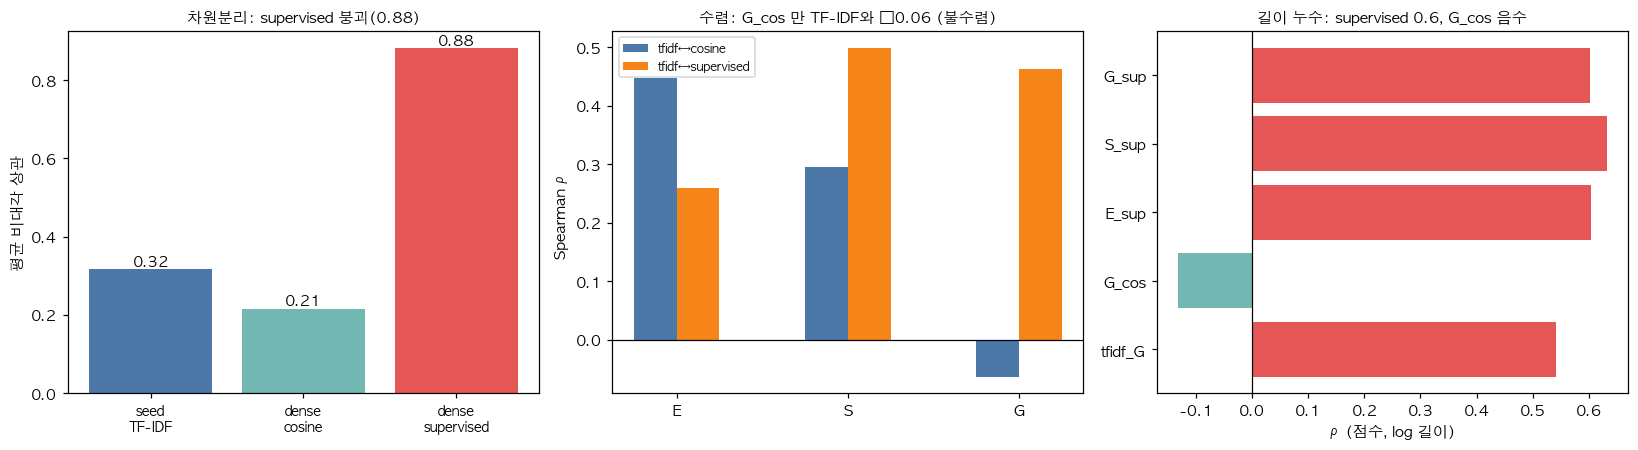

In [5]:
sep=L('h4_dimension_separation'); conv=L('h4_cross_track_convergence'); ln=L('h4_length_sensitivity')
bleed=L('h4_sentence_bleed'); bex=L('h4_sentence_bleed_examples')
print('▶ 차원 간 상관 (낮을수록 잘 분리)'); display(sep)
print('▶ 수렴타당도: dense 가 TF-IDF 와 같은 차원을 보나 (G_cos 가 핵심)'); display(conv)
print('▶ 길이 민감도'); display(ln)
print('▶ 문장 단위: 앵커 상위50 문장의 키워드 점유 (own=자기차원, other=타차원)'); display(bleed)
print('▶ 예시 문장'); display(bex)

fig,ax=plt.subplots(1,3,figsize=(15,4.2))
x=np.arange(3);w=.25
ax[0].bar(x,sep['mean_offdiag'],color=['#4C78A8','#72B7B2','#E45756'])
ax[0].set_xticks(x);ax[0].set_xticklabels(['seed\nTF-IDF','dense\ncosine','dense\nsupervised'],fontsize=9)
ax[0].set_ylabel('평균 비대각 상관'); ax[0].set_title('차원분리: supervised 붕괴(0.88)',fontsize=10)
for i,v in enumerate(sep['mean_offdiag']): ax[0].text(i,v+.01,f'{v:.2f}',ha='center')
xc=np.arange(3)
ax[1].bar(xc-w/2,conv['tfidf~cosine'],w,label='tfidf↔cosine',color='#4C78A8')
ax[1].bar(xc+w/2,conv['tfidf~supervised'],w,label='tfidf↔supervised',color='#F58518')
ax[1].axhline(0,color='k',lw=.8);ax[1].set_xticks(xc);ax[1].set_xticklabels(conv['dimension'])
ax[1].set_title('수렴: G_cos 만 TF-IDF와 −0.06 (불수렴)',fontsize=10);ax[1].set_ylabel('Spearman ρ');ax[1].legend(fontsize=8)
sub=ln[ln.score.isin(['tfidf_G','G_cos','G_sup','E_sup','S_sup'])]
ax[2].barh(sub['score'],sub['rho_log_core_len'],color=['#E45756' if v>.4 else '#72B7B2' for v in sub['rho_log_core_len']])
ax[2].axvline(0,color='k',lw=.8);ax[2].set_xlabel('ρ(점수, log 길이)');ax[2].set_title('길이 누수: supervised 0.6, G_cos 음수',fontsize=10)
plt.tight_layout(); plt.savefig(FIG/'08_h4_dense_failure.png',bbox_inches='tight'); plt.show()

**해석 가이드 (H4 = "차원누수"는 약하고, 진짜는 *선택성 복제 실패* + 단일요인)**
- **단순 "차원 누수"는 주원인이 아니다.** dense cosine 은 화이트닝 후 **차원분리가 오히려 양호**(비대각 0.21 < TF‑IDF
  0.32)하고, **앵커 상위 문장도 대체로 자기차원**(E 56%·G 60% own 키워드, 타차원 6~8%). 즉 문장검색은 정상.
- **진짜 원인 ①: dense G_cos 가 실제 G 신호와 *불수렴*.** `tfidf_G ↔ G_cos = −0.06`(E는 +0.45, S는 +0.30)이고
  G_cos 는 길이와 **음(−0.13)** → G에서 *잡음* 을 잡는다. **진짜 원인 ②: supervised 가 단일 길이요인으로 붕괴**
  (비대각 **0.88**, 길이 상관 **0.6**) → 차원 구분 자체가 사라짐.
- **통합 메커니즘(H2와 연결)**: **TF‑IDF의 IDF 가중**은 희소·변별 컴플라이언스어를 *분리·증폭* 하지만, **임베딩은
  "거버넌스스러운" 의미유사도**를 재고 그 유사도는 **모든 보고서에 있는 보일러플레이트(감사위원회·이사회 섹션)** 가
  지배 → max 풀링하면 다 비슷해 **변별 실패**. **dense 는 IDF의 선택성을 복제하지 못한다.**
- **결론**: dense 가 G에서 실패하는 건 임베딩이 *선택적 하위어휘* 를 분리 못 하기 때문(+전반적 길이·단일요인 지배).
  *"왜 TF‑IDF만 G를 잡나"* 의 답. (정식 화이트닝은 Colab 산출물이라 ④는 근사·예시: `dense_기록 §12`.)

## 종합 — "왜 G만 남았는가?" 최종 설명

,가설,순위/판정,지원 증거,반박/한계
0,H2 G 측정가능성,★ 1위 (강),"컴플라이언스/윤리 어휘가 변별: 밀도↔tfidf_G +.41, ↔g .29; 상위 vs 하위 p=.0007",보일러플레이트(이사회·감사위원회)는 역신호; 신호 자체 약(0.38·부분ρ.17)
1,H1 KCGS 구조,2위 (부분),통합등급≈G: 분해 β(G)=0.92≫E.38/S.44; tfidf_G→통합ESG=0.50*** 최강,분리 g등급만 써도 G만 생존(0.38**)·E/S는 자기등급서 사망 → 유일생존의 근본원인 아님
2,H3 사전 품질,3위 (약),S는 보편어로 희석(안전91%/지역90%/노동ρ≈0); G가 가장 선택적(중앙df 19%),"45 term 전부 +상관, E 평균ρ(.26)>G(.24) → ""부실"" 아님; H2의 이면"
3,H4 Dense 실패,별개 질문,임베딩은 IDF 선택성 복제 못함; G_cos↔tfidf_G −.06; supervised 단일요인(.88),"문장검색·차원분리는 정상 → 단순 ""누수"" 아님. ""왜 dense 아닌 TF-IDF""의 답"


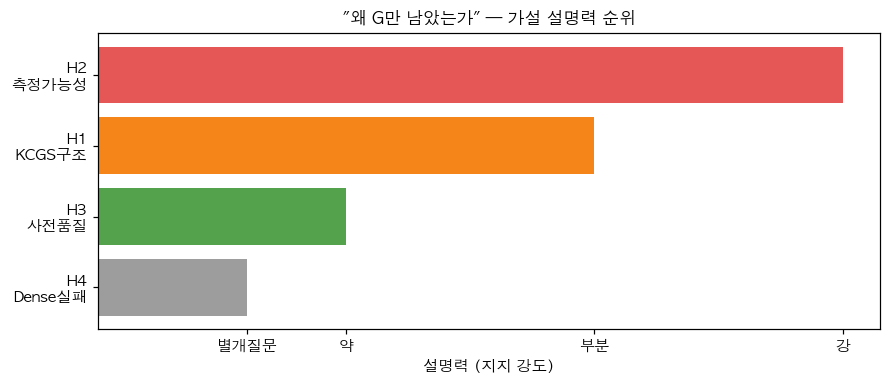

In [6]:
ev=pd.DataFrame([
 ['H2 G 측정가능성','★ 1위 (강)','컴플라이언스/윤리 어휘가 변별: 밀도↔tfidf_G +.41, ↔g .29; 상위 vs 하위 p=.0007',
  '보일러플레이트(이사회·감사위원회)는 역신호; 신호 자체 약(0.38·부분ρ.17)'],
 ['H1 KCGS 구조','2위 (부분)','통합등급≈G: 분해 β(G)=0.92≫E.38/S.44; tfidf_G→통합ESG=0.50*** 최강',
  '분리 g등급만 써도 G만 생존(0.38**)·E/S는 자기등급서 사망 → 유일생존의 근본원인 아님'],
 ['H3 사전 품질','3위 (약)','S는 보편어로 희석(안전91%/지역90%/노동ρ≈0); G가 가장 선택적(중앙df 19%)',
  '45 term 전부 +상관, E 평균ρ(.26)>G(.24) → "부실" 아님; H2의 이면'],
 ['H4 Dense 실패','별개 질문','임베딩은 IDF 선택성 복제 못함; G_cos↔tfidf_G −.06; supervised 단일요인(.88)',
  '문장검색·차원분리는 정상 → 단순 "누수" 아님. "왜 dense 아닌 TF-IDF"의 답'],
],columns=['가설','순위/판정','지원 증거','반박/한계'])
display(ev)
fig,ax=plt.subplots(figsize=(8.2,3.6))
labels=['H2\n측정가능성','H1\nKCGS구조','H3\n사전품질','H4\nDense실패']
strength=[3,2,1,0.6]; cols=['#E45756','#F58518','#54A24B','#9D9D9D']
ax.barh(range(4)[::-1],strength,color=cols)
ax.set_yticks(range(4)[::-1]);ax.set_yticklabels(labels)
ax.set_xlabel('설명력 (지지 강도)'); ax.set_title('"왜 G만 남았는가" — 가설 설명력 순위',fontsize=11)
ax.set_xticks([0.6,1,2,3]);ax.set_xticklabels(['별개질문','약','부분','강'])
plt.tight_layout(); plt.savefig(FIG/'08_synthesis_ranking.png',bbox_inches='tight'); plt.show()

"텍스트↔등급 관계의 대부분은 규모·분량 교란이고, 그걸 다 걷어내면 G에만 약한 진짜 신호가 남는다"

 "규모·분량을 통제하면 텍스트 신호의 대부분이 사라지며, G 차원에서만 약한 잔여 신호(ρ=0.17)가 관찰된다. 이는 사업보고서 서술이 ESG 등급의 독립적 예측인자라기보다, 규모·공시충실도의 대리지표에 가깝다는 것을 시사한다."

### 최종 답 — *"왜 G만 남았는가?"*

> **거버넌스(G) 공시에는 *변별력 있는 선택적 하위어휘*(컴플라이언스·윤리·부패방지)가 존재하고, TF‑IDF의 IDF 가중이
> 이를 분리·증폭한다. 그래서 길이·규모·업종·연도를 모두 통제해도 G만 살아남는다.** 더 높은 G 기업(대한전선·CJ·한진 …)은
> 준법지원인·컴플라이언스·청탁금지법 같은 *선택적* 거버넌스 활동을 더 많이 공시하고, 낮은 기업은 *의무* 보일러플레이트
> (주주총회·감사위원회 활동)만 둔다 — 그리고 그 보일러플레이트는 모든 보고서에 있어 변별에 무용하다(역신호).

**왜 E·S는 못 남았나** — 같은 동전의 이면: **S 신호는 보편어(안전 91%·지역 90%·임직원 76%)에 희석**되고 **E는 일반
운영어(활용·자원·사용량)와 섞여**, 길이·규모를 통제하면 *선택적 핵심* 만 남지 않는다(H3·H2 결합). **KCGS 통합등급이
구조적으로 G에 실려(β 0.92)** G의 우위가 *통합분석에서* 더 증폭되며(H1), **dense 임베딩은 IDF의 선택성을 복제 못 해
바로 그 G에서 실패**한다(H4).

**순위**: **① H2(선택적 컴플라이언스 어휘) — 가장 직접·강건 → ② H1(통합등급 G가중 증폭) → ③ H3(S/E 희석, H2의 이면)
→ ④ H4(별개: 방법 의존성).** H2·H3·H1·H4 는 *경쟁* 이 아니라 하나의 그림으로 합쳐진다: **"G에는 IDF가 잡아낼 선택적
컴플라이언스 어휘가 있다."**

**한계(반드시 병기)**: 신호는 *약하다* — 매칭 0.38\*\*·부분ρ 0.17·기업부트 CI [.04,.30](`TF‑IDF_기록 §12.2b`).
**"유의 ≠ 중요"**. 관찰연구라 **인과 아님**(공시 강도 ≠ 실제 거버넌스 성과 = cheap‑talk 가능). n=381·기업 127.
상/하위 10 비교는 길이에 교란되니 *탐색적* 이며, 통제 회귀가 본증거다.

---
*산출: 표 `data/processed/08_*.csv` · 그림 `reports/figures/08_*.png` · 엔진 `analysis/08_why_g.py` ·
요약 `왜_G만_남았나_기록.md`. 기존 결론은 `종합_기록.md`·`TF‑IDF_기록.md`·`dense_기록.md`.*